# 06 - K-Means clustering of director profiles (+ hierarchical clustering)

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
def show(f, w=900): display(Image(filename=str(ROOT / 'outputs' / 'plots' / f), width=w))

In [2]:
from src.clustering import kmeans
s = kmeans.run()
{k: s[k] for k in ['chosen_k','silhouette','davies_bouldin','cluster_sizes','manual_vs_sklearn']}

2026-11-21 13:05:32,264 | kmeans | INFO | PHASE 8b - K-Means started


2026-11-21 13:05:48,370 | kmeans | INFO | PHASE 8b complete: K=3 silhouette=0.126 agreement={'ari_manual_vs_sklearn_same_init': 1.0, 'wcss_manual': 10784.788699749864, 'wcss_sklearn_same_init': 10784.788699749864, 'ari_manual_vs_sklearn_best_of_20': 0.46750593324429185, 'wcss_sklearn_best_of_20': 10761.507282033996, 'manual_iterations': 16, 'manual_time_s': 0.013342099962756038, 'sklearn_time_s': 0.00907329993788153}


{'chosen_k': 3,
 'silhouette': 0.12561936069839527,
 'davies_bouldin': 2.123761847191748,
 'cluster_sizes': {0: 315, 1: 21, 2: 346},
 'manual_vs_sklearn': {'ari_manual_vs_sklearn_same_init': 1.0,
  'wcss_manual': 10784.788699749864,
  'wcss_sklearn_same_init': 10784.788699749864,
  'ari_manual_vs_sklearn_best_of_20': 0.46750593324429185,
  'wcss_sklearn_best_of_20': 10761.507282033996,
  'manual_iterations': 16,
  'manual_time_s': 0.013342099962756038,
  'sklearn_time_s': 0.00907329993788153}}

In [3]:
pd.read_csv('outputs/kmeans/k_selection_metrics.csv')

,k,wcss,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size,wcss_second_difference
0,2,11631.487362,0.105369,2.715336,77.550580,306,NaN
1,3,10761.507282,0.125619,2.123762,69.294129,21,78.312486
2,4,9969.839688,0.111863,1.975931,67.736719,19,285.489848
3,5,9463.661941,0.123916,1.807424,62.493432,17,64.142858
4,6,9021.627052,0.121896,1.772565,58.991313,14,9.402449
5,7,8588.994612,0.126597,1.767523,57.225919,14,-16.034472
6,8,8140.327700,0.140418,1.750752,56.984563,17,-22.771080
7,9,7668.889709,0.151230,1.588323,58.019664,11,185.729556
8,10,7383.181273,0.150028,1.566646,56.378560,11,NaN


In [4]:
pd.read_csv('outputs/kmeans/cluster_profiles.csv')

,cluster,size,n_films,first_year,mean_year,career_span,share_color,share_tv,mean_halliwell,share_rated,oscar_nom_rate,mean_cast_size,share_Dram,share_Comd,share_Susp,share_Romt,share_Horr,share_Musc,share_West,share_Advt,share_Actn,share_Docu,example_directors,most_common_country,label
0,0,315,12.546,1932.660,1942.975,23.371,0.206,0.005,1.349,0.356,0.039,3.641,0.178,0.141,0.040,0.062,0.016,0.055,0.028,0.040,0.016,0.013,"Cukor, Curtiz, Lubitsch, Griffith, J.Ford, I.Bergman",USA,"classical, drama-leaning"
1,1,21,17.762,1957.143,1963.451,13.810,0.285,0.649,0.963,0.102,0.004,4.296,0.070,0.006,0.747,0.031,0.008,0.000,0.003,0.009,0.013,0.002,"Hitchcock, R.Stevens, Henreid, Daugherty, N.Lloyd, Crosland jr",USA,"post-studio, suspense-leaning, TV-heavy"
2,2,346,9.301,1968.017,1978.187,21.032,0.928,0.019,0.822,0.203,0.035,4.072,0.180,0.131,0.044,0.078,0.053,0.020,0.015,0.042,0.060,0.031,"Hiller, G.Thomas, Lumet, Corman, Spielberg, Woody Allen",USA,"modern, drama-leaning"


In [5]:
pd.read_csv('outputs/kmeans/hierarchical_comparison.csv')

,linkage,cophenetic_correlation,clusters,largest_cluster,smallest_cluster,silhouette,ari_vs_kmeans
0,single,0.708673,3,678,1,0.415304,-0.001052
1,complete,0.624400,3,662,5,0.298147,-0.003622
2,average,0.776055,3,676,2,0.421471,-0.001815
3,ward,0.298850,3,459,18,0.076765,0.115072


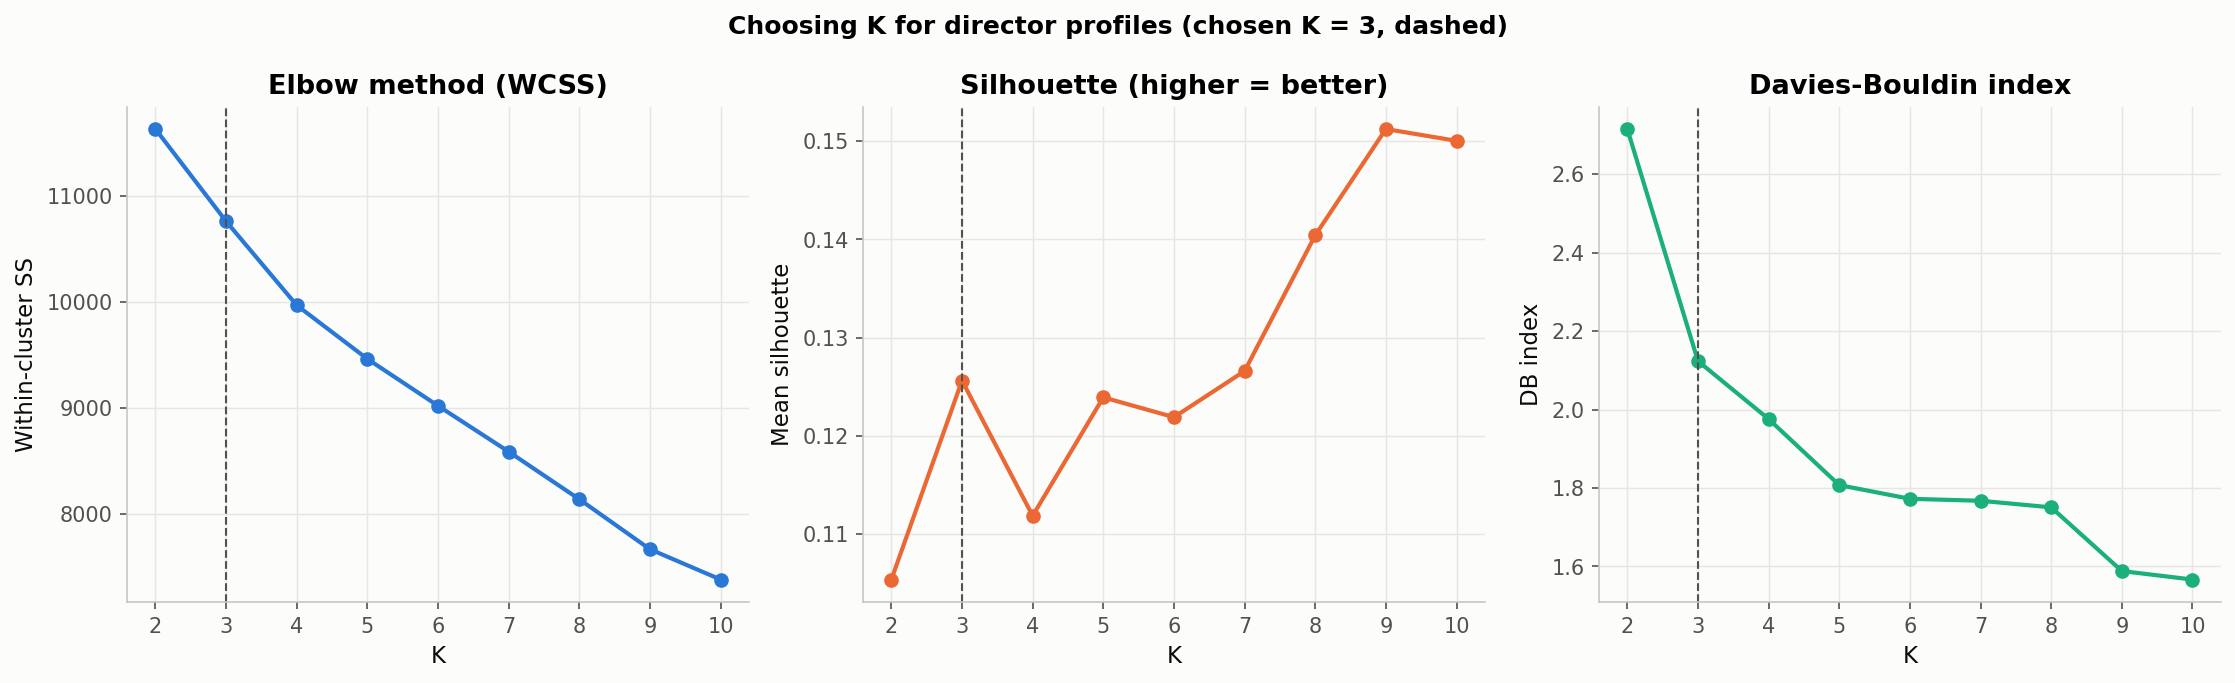

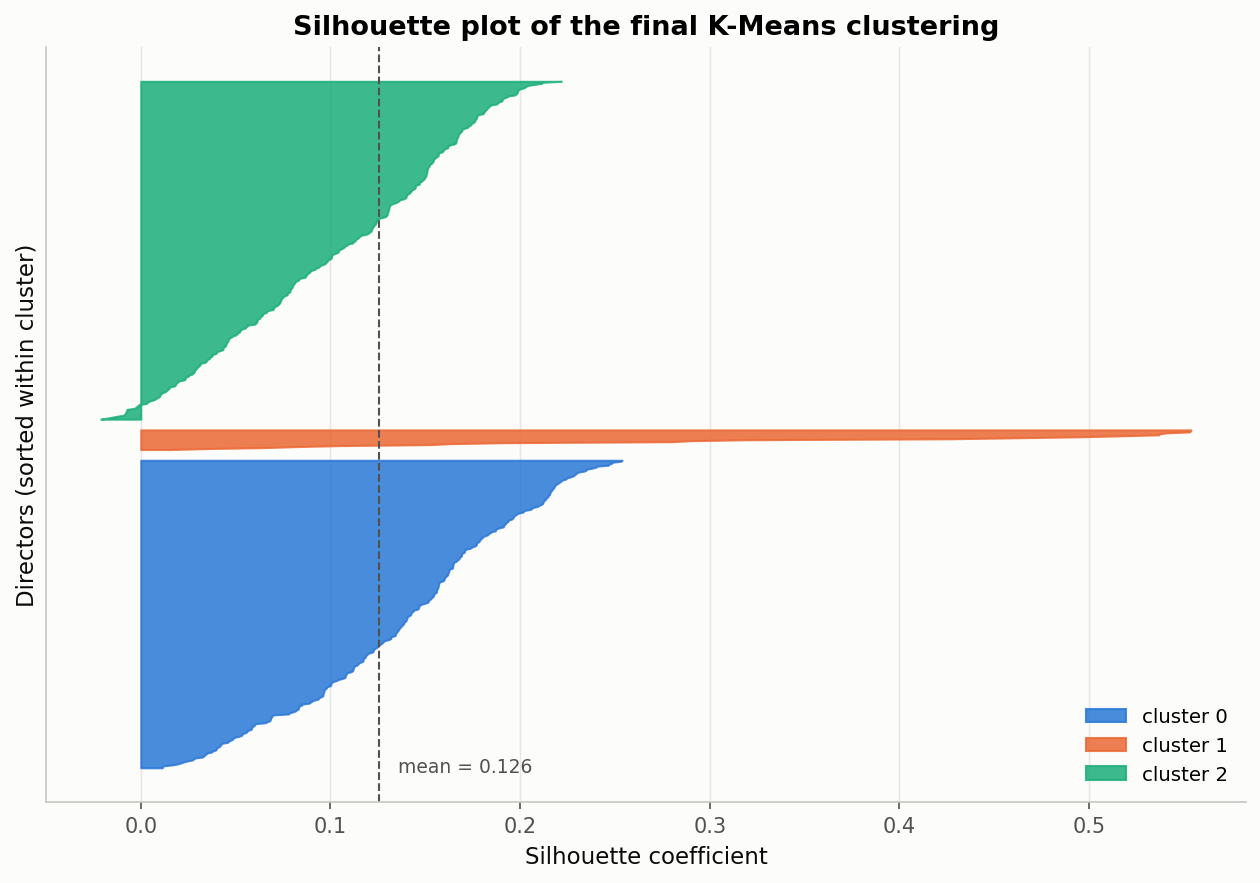

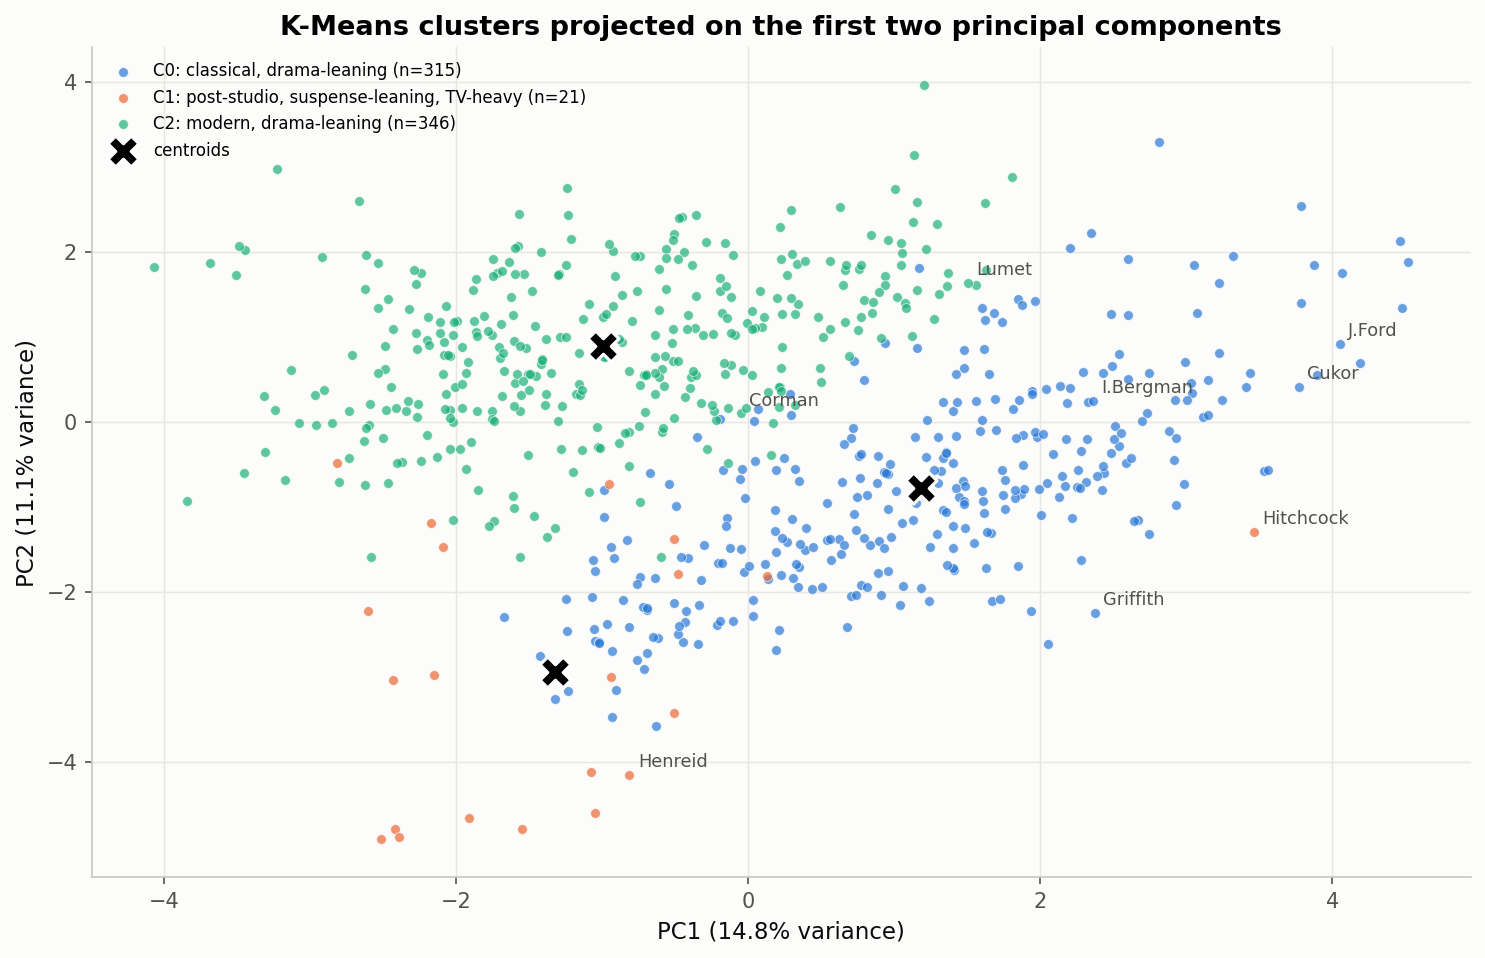

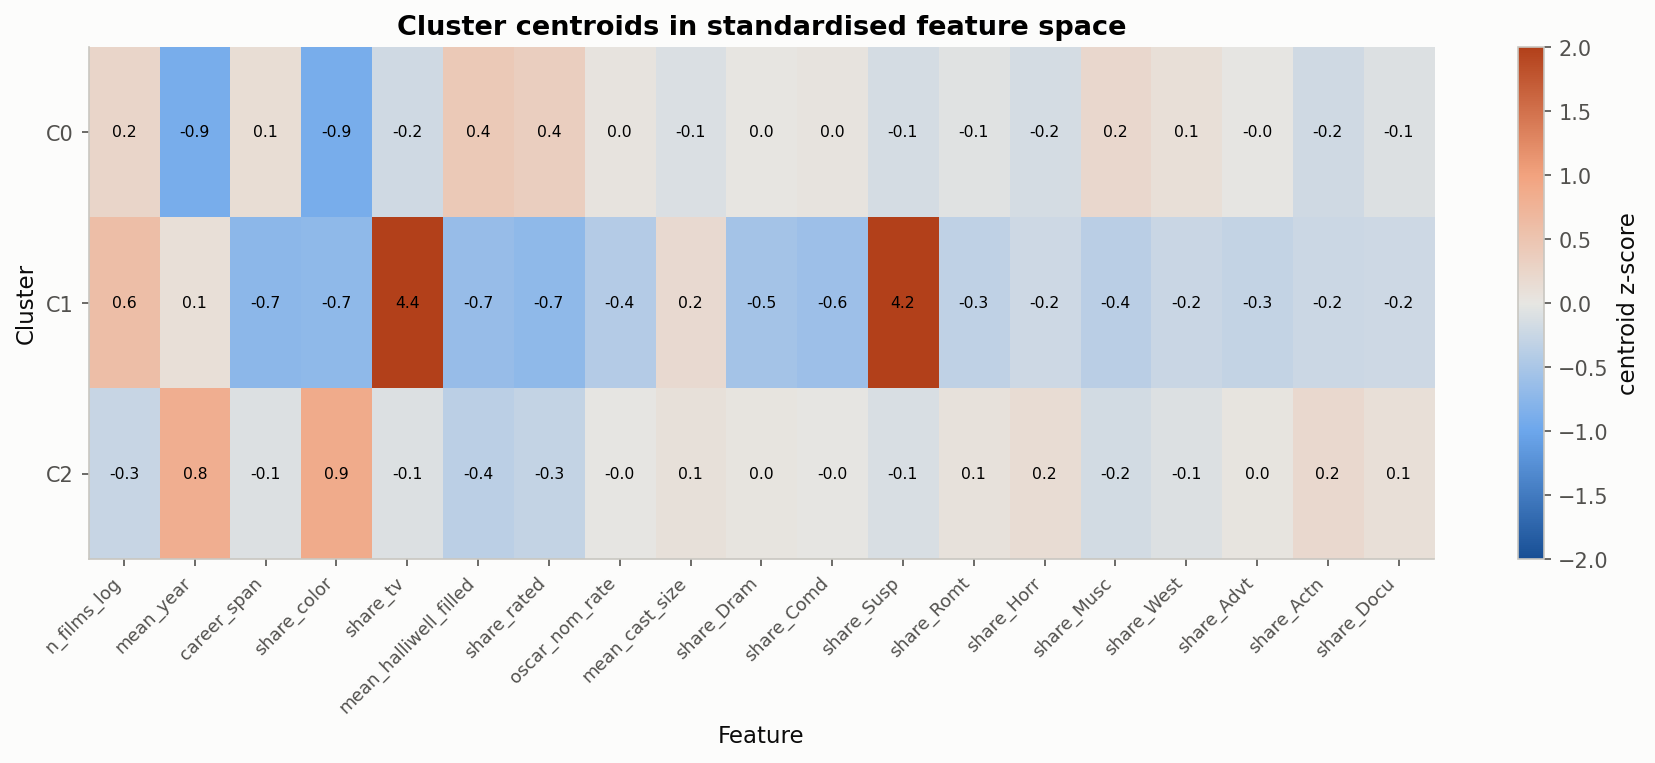

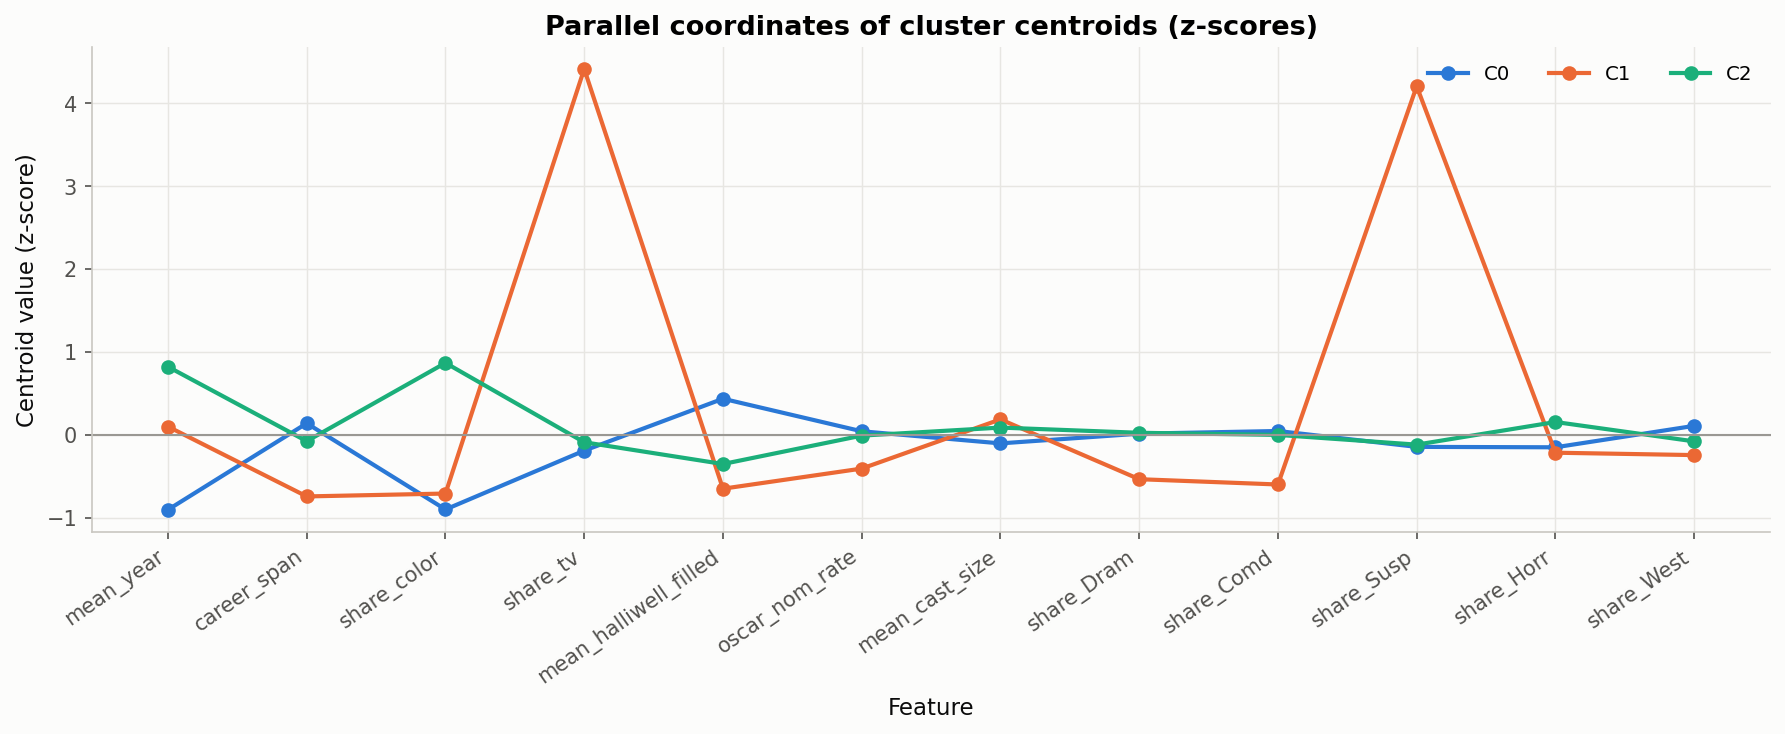

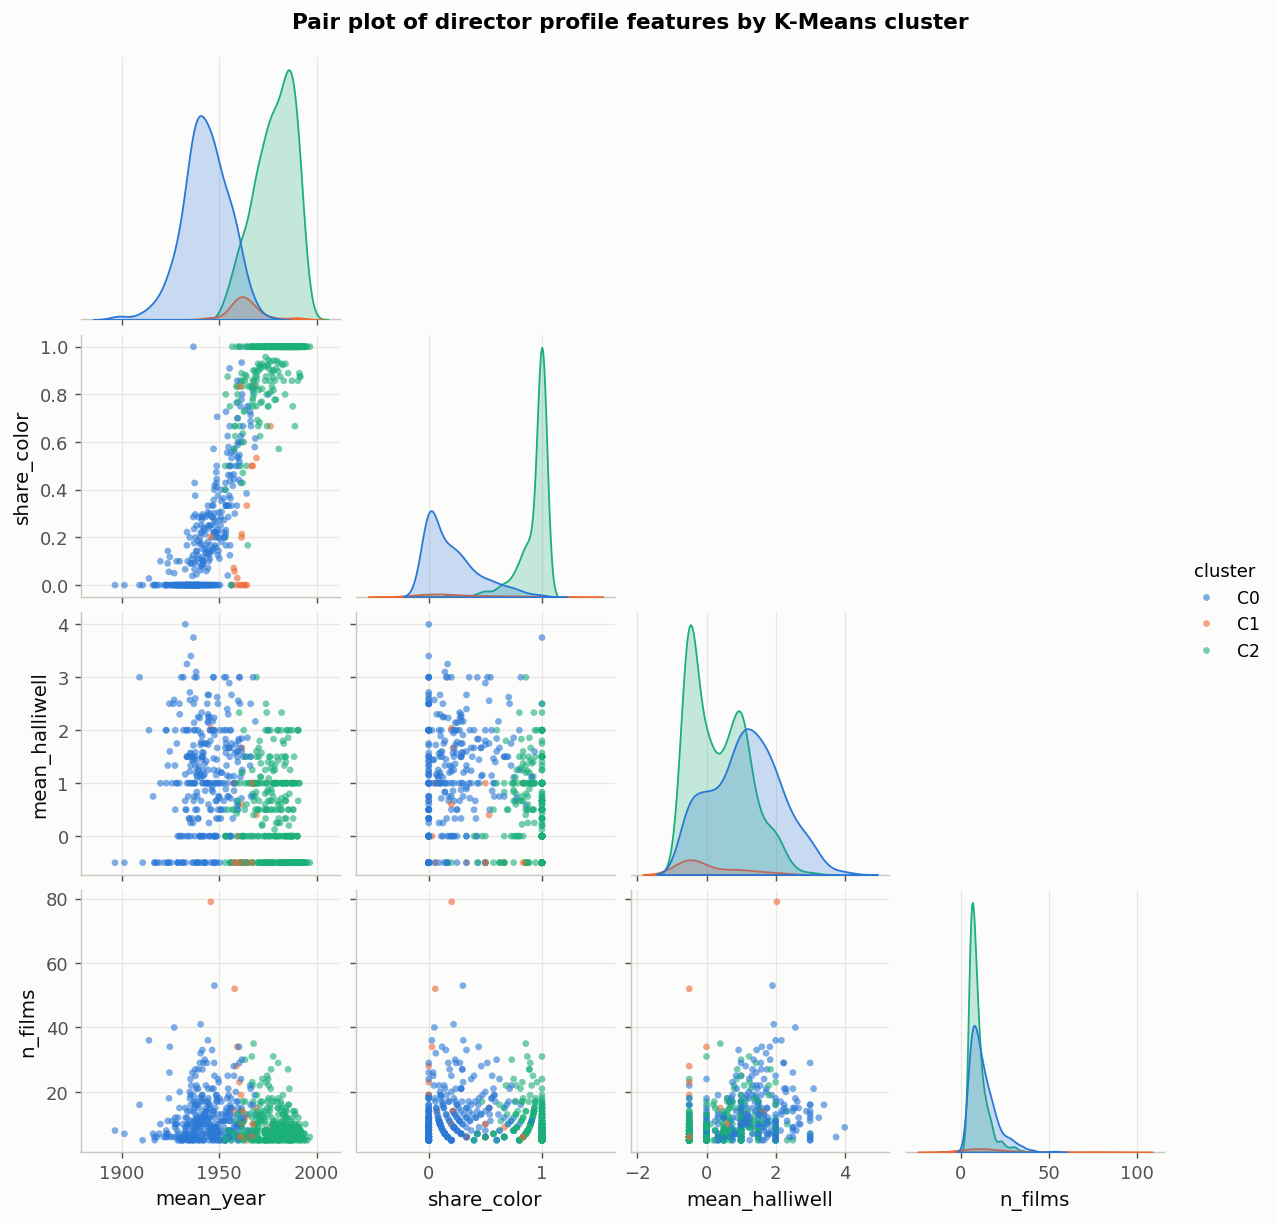

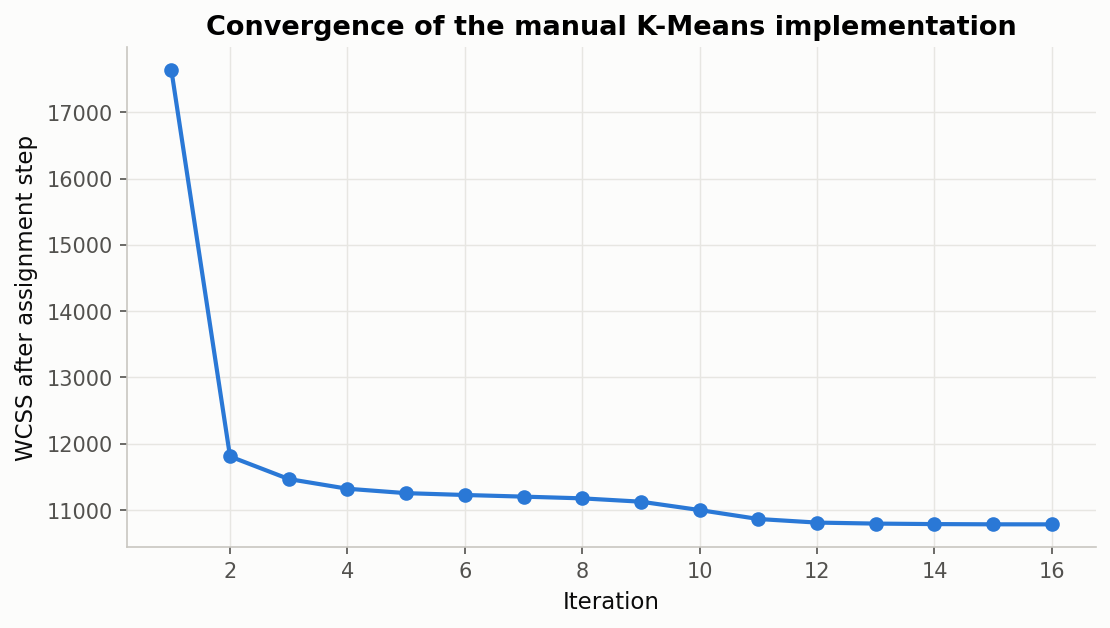

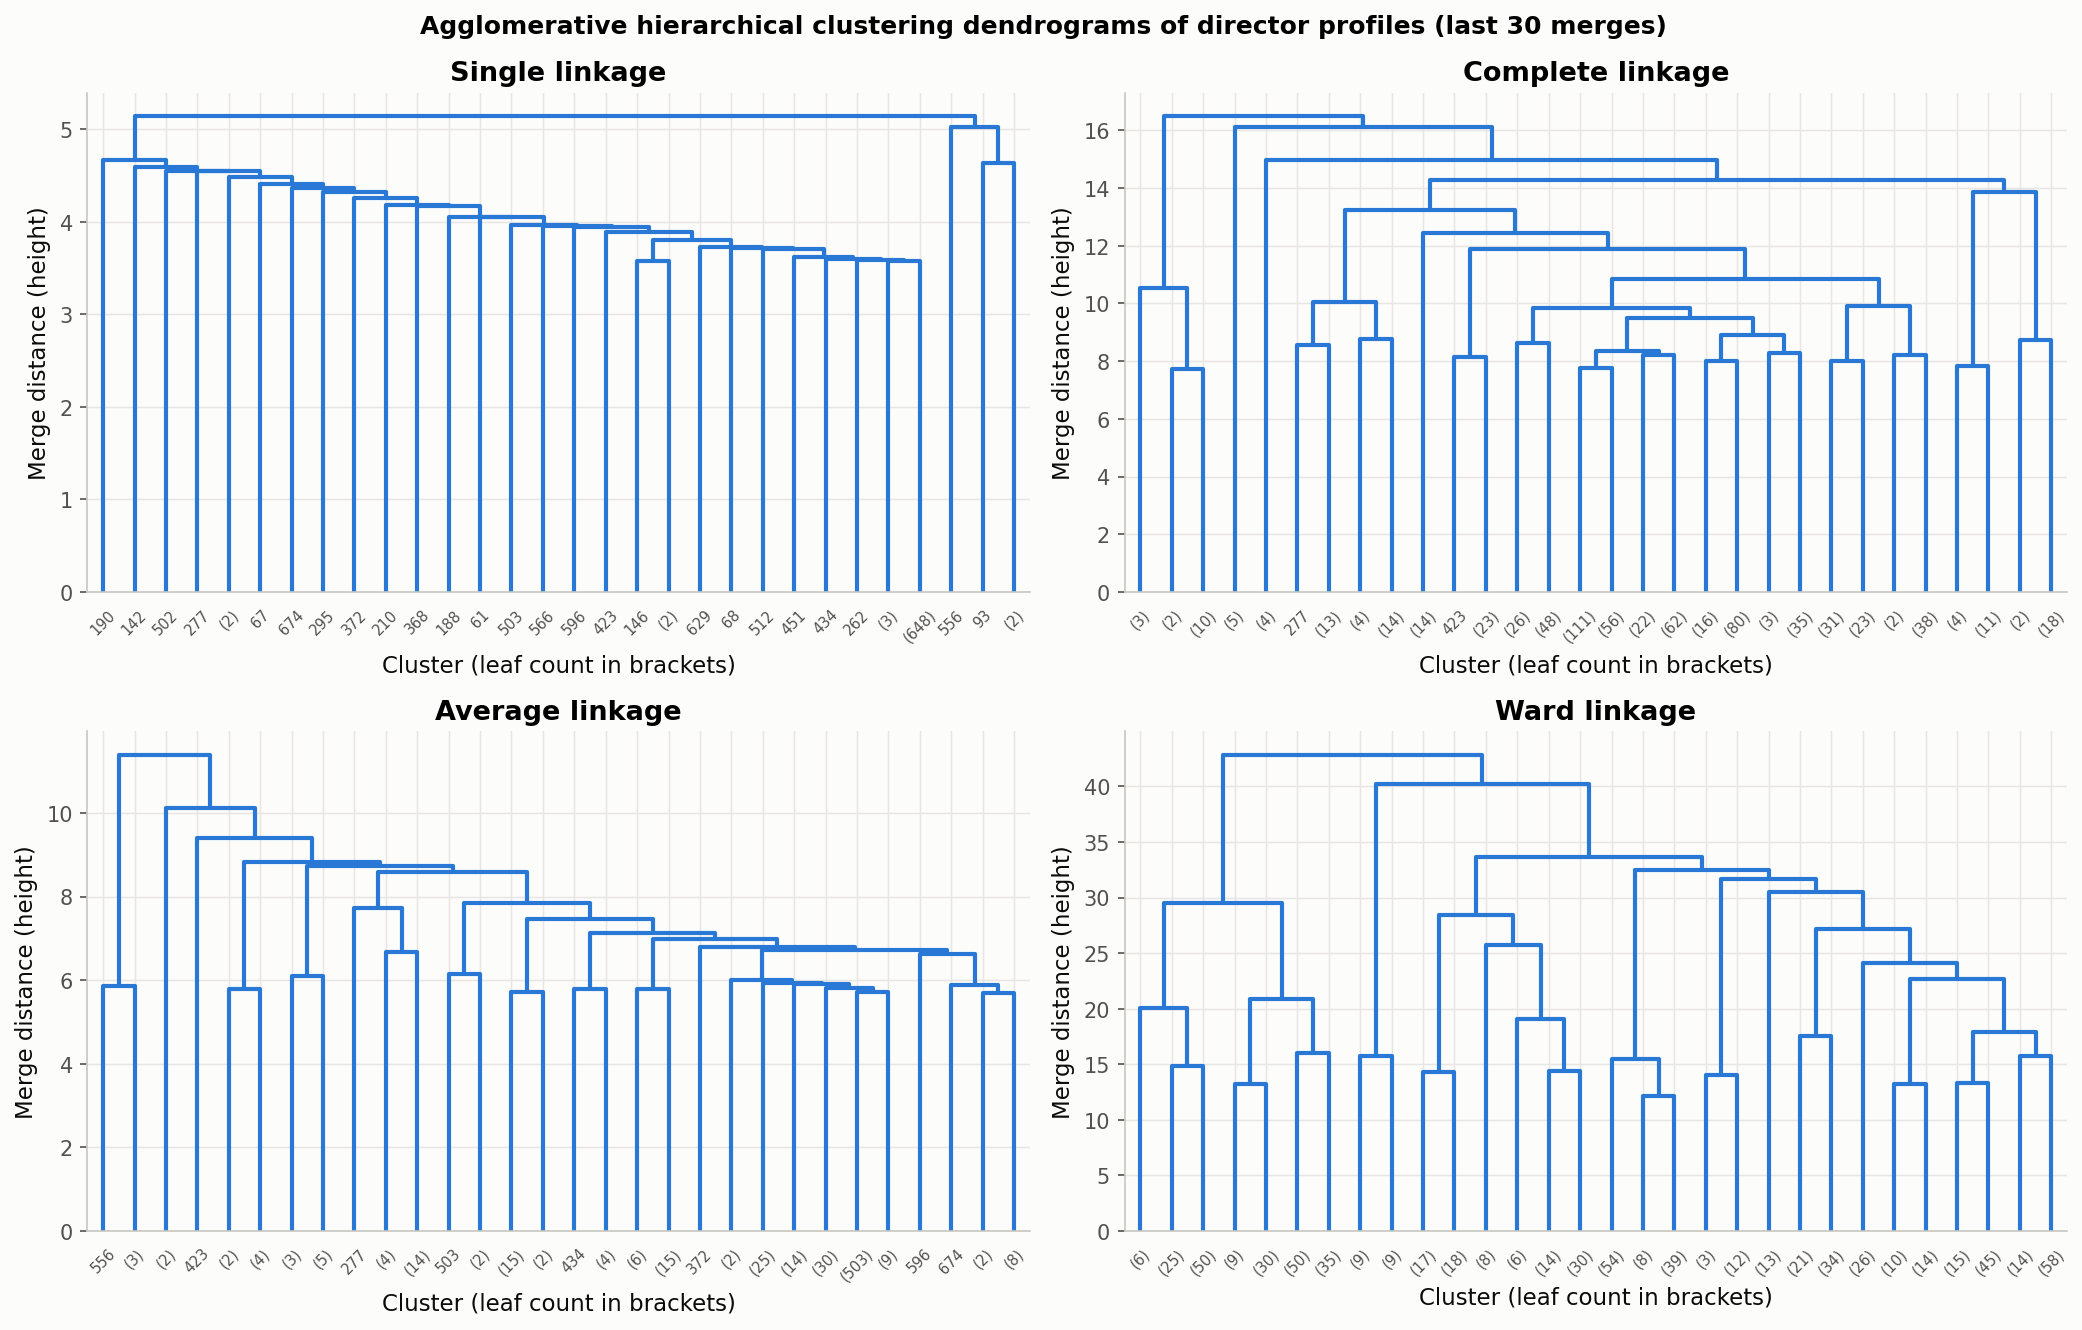

In [6]:
for f in ['29_kmeans_elbow_silhouette_db.png','30_kmeans_silhouette_plot.png','31_kmeans_pca_clusters.png','33_kmeans_centroid_heatmap.png','34_kmeans_parallel_coordinates.png','35_kmeans_pairplot.png','36_kmeans_manual_convergence.png','37_hierarchical_dendrograms.png']: show(f)